# Bài 06 - Phần 3: RNN bằng PyTorch trên hai bộ dữ liệu

Notebook này cài ba loại ô hồi quy (RNN thuần, LSTM, GRU) bằng PyTorch rồi dùng chúng
cho hai bài toán đã chuẩn bị ở notebook 02:

- **Churn**: phân lớp khách rời bỏ, mỗi khách là một chuỗi 11 đặc trưng.
- **AMZN**: dự báo lợi suất phiên kế tiếp và dự báo biến động 5 phiên tới, đầu vào là
  cửa sổ 60 phiên x 3 đặc trưng.

Mọi thứ không thuộc về mô hình (chia tập, chuẩn hóa, siêu tham số, độ đo, baseline)
lấy từ `lab06_data.py`, file mà notebook 04 (Keras) cũng dùng. Mỗi cấu hình chạy với
3 hạt giống ngẫu nhiên, bảng kết quả ghi trung bình ± độ lệch chuẩn, còn hình vẽ lấy
từ lần chạy với hạt giống 42.

In [1]:
import copy
import time

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.decomposition import PCA
from sklearn.metrics import precision_recall_curve, roc_curve

import lab06_data as D

torch.set_num_threads(8)
SEEDS = (42, 43, 44)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 130, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.width", 140)
COLORS = {"LogReg": "#937860", "MLP": "#8C8C8C", "RNN": "#4C72B0", "LSTM": "#DD8452",
          "GRU": "#55A868"}


def save(fig, name):
    fig.savefig(D.RESULTS / name, bbox_inches="tight")


print("torch", torch.__version__, "| threads", torch.get_num_threads())
print("sieu tham so churn:", D.CHURN_HP)
print("sieu tham so stock:", D.STOCK_HP)

torch 2.10.0+cpu | threads 8
sieu tham so churn: {'hidden': 32, 'lr': 0.003, 'batch': 64, 'epochs': 60, 'patience': 10}
sieu tham so stock: {'hidden': 32, 'lr': 0.001, 'batch': 64, 'epochs': 40, 'patience': 8, 'dropout': 0.2}


## 1. Mô hình

Cả hai bài toán đều thuộc dạng **nhiều-một** (many-to-one): mạng đọc hết chuỗi rồi
mới đưa ra một số. `SeqNet` bọc một tầng `nn.RNN`, `nn.LSTM` hoặc `nn.GRU`, lấy trạng
thái ẩn ở bước cuối cùng `out[:, -1]` rồi đưa qua một lớp tuyến tính. Đầu ra là một
số thực chưa qua hàm kích hoạt: với bài phân lớp đó là logit (hàm mất mát
`BCEWithLogitsLoss` tự áp sigmoid, ổn định số hơn tự gọi `sigmoid` rồi `BCELoss`), với
bài hồi quy đó chính là giá trị dự báo.

`MLP` là đối chứng không hồi quy: nó nhận cả 11 đặc trưng cùng lúc. Nếu RNN không hơn
MLP thì cấu trúc hồi quy không mang lại gì cho dữ liệu dạng bảng.

In [2]:
class SeqNet(nn.Module):
    """Mang nhieu-mot: o hoi quy doc ca chuoi, lay trang thai an cuoi, qua lop Linear."""

    def __init__(self, cell, n_in, hidden, dropout=0.0):
        super().__init__()
        layer = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell]
        self.rnn = layer(n_in, hidden, batch_first=True)   # vao: (batch, time, feature)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x, return_hidden=False):
        out, _ = self.rnn(x)                 # out: (batch, time, hidden)
        h_last = out[:, -1]                  # trang thai an o buoc cuoi: (batch, hidden)
        y = self.head(self.drop(h_last)).squeeze(-1)
        return (y, h_last) if return_hidden else y


class MLP(nn.Module):
    """Doi chung khong hoi quy: nhan ca chuoi cung luc nhu mot vecto phang."""

    def __init__(self, n_in, hidden):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(n_in, hidden), nn.ReLU(),
                                 nn.Linear(hidden, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


H = D.CHURN_HP["hidden"]
for name, m in [("MLP", MLP(11, H)), ("RNN", SeqNet("RNN", 1, H)),
                ("LSTM", SeqNet("LSTM", 1, H)), ("GRU", SeqNet("GRU", 1, H))]:
    print("%-5s %6d tham so" % (name, n_params(m)))
print(SeqNet("LSTM", 1, H))

MLP      417 tham so
RNN     1153 tham so
LSTM    4513 tham so
GRU     3393 tham so
SeqNet(
  (rnn): LSTM(1, 32, batch_first=True)
  (drop): Dropout(p=0.0, inplace=False)
  (head): Linear(in_features=32, out_features=1, bias=True)
)


Số tham số của tầng hồi quy khớp với công thức ở notebook 01: với đầu vào F và trạng
thái ẩn H, `nn.RNN` có H(F + H + 2) tham số (PyTorch giữ hai vectơ bias `b_ih` và
`b_hh`), `nn.GRU` gấp 3 lần và `nn.LSTM` gấp 4 lần con số đó. Với F = 1, H = 32:
RNN 1.120 + 33 của lớp đầu ra, GRU 3.360 + 33, LSTM 4.480 + 33.

## 2. Vòng lặp huấn luyện

Một hàm `fit` dùng cho mọi mô hình: Adam, cắt chuẩn gradient về tối đa 1 (chống bùng
nổ gradient, vấn đề đã đo ở notebook 01), trộn mẫu mỗi epoch bằng một bộ sinh số có
hạt giống riêng, và dừng sớm khi loss validation không giảm sau `patience` epoch. Khi
dừng, trọng số được trả về trạng thái có loss validation thấp nhất.

In [3]:
def fit(model, data, loss_fn, hp, seed):
    """Adam + cat gradient + dung som theo loss validation. Tra ve lich su tung epoch."""
    g = torch.Generator().manual_seed(seed)
    Xtr, ytr = torch.as_tensor(data["X_train"]), torch.as_tensor(data["y_train"])
    Xva, yva = torch.as_tensor(data["X_val"]), torch.as_tensor(data["y_val"])
    opt = torch.optim.Adam(model.parameters(), lr=hp["lr"])
    hist = {"train_loss": [], "val_loss": []}
    best, best_state, wait = np.inf, None, 0
    t0 = time.perf_counter()
    for epoch in range(hp["epochs"]):
        model.train()
        total = 0.0
        perm = torch.randperm(len(Xtr), generator=g)
        for i in range(0, len(Xtr), hp["batch"]):
            b = perm[i:i + hp["batch"]]
            opt.zero_grad()
            loss = loss_fn(model(Xtr[b]), ytr[b])
            loss.backward()                                   # BPTT qua ca chuoi
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item() * len(b)
        model.eval()
        with torch.no_grad():
            vl = loss_fn(model(Xva), yva).item()
        hist["train_loss"].append(total / len(Xtr))
        hist["val_loss"].append(vl)
        if vl < best - 1e-6:
            best, best_state, wait = vl, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= hp["patience"]:
                break
    model.load_state_dict(best_state)
    return dict(history=hist, epochs=epoch + 1,
                best_epoch=int(np.argmin(hist["val_loss"])) + 1,
                seconds=round(time.perf_counter() - t0, 2))


def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.as_tensor(X)).numpy().astype(np.float64)


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def summarize(runs, keys):
    """Trung binh va do lech chuan qua cac hat giong cho tung do do."""
    return {k: (float(np.mean([r["metrics"][k] for r in runs])),
                float(np.std([r["metrics"][k] for r in runs]))) for k in keys}

## 3. Churn: phân lớp khách hàng rời bỏ

### 3.1. Huấn luyện bốn mô hình với ba hạt giống

In [4]:
C = D.churn_splits()


def as_seq(X):
    return X[:, :, None]          # (N, 11) -> (N, 11 buoc, 1 dac trung)


churn_data = dict(X_train=as_seq(C["X_train"]), y_train=C["y_train"],
                  X_val=as_seq(C["X_val"]), y_val=C["y_val"])
bce = nn.BCEWithLogitsLoss()
churn_makers = {"MLP": lambda: MLP(11, H), "RNN": lambda: SeqNet("RNN", 1, H),
                "LSTM": lambda: SeqNet("LSTM", 1, H), "GRU": lambda: SeqNet("GRU", 1, H)}


def run_churn(make, data, X_test, seed, hp=D.CHURN_HP):
    torch.manual_seed(seed)
    model = make()
    info = fit(model, data, bce, hp, seed)
    p_val = sigmoid(predict(model, data["X_val"]))
    p_test = sigmoid(predict(model, X_test))
    thr = D.best_threshold(C["y_val"], p_val)
    return model, dict(seed=seed, metrics=D.cls_metrics(C["y_test"], p_test, thr),
                       p_test=p_test, **info)


churn_runs, churn_models = {}, {}
for name, make in churn_makers.items():
    churn_runs[name] = []
    for seed in SEEDS:
        model, r = run_churn(make, churn_data, as_seq(C["X_test"]), seed)
        churn_runs[name].append(r)
        if seed == SEEDS[0]:
            churn_models[name] = model
        print("%-5s seed %d: AUC %.4f  F1 %.4f  %2d epoch  %5.1f s"
              % (name, seed, r["metrics"]["roc_auc"], r["metrics"]["f1"], r["epochs"],
                 r["seconds"]))

pv_lr, pt_lr = D.churn_logreg(C)
logreg = D.cls_metrics(C["y_test"], pt_lr, D.best_threshold(C["y_val"], pv_lr))
print("LogReg      : AUC %.4f  F1 %.4f" % (logreg["roc_auc"], logreg["f1"]))

MLP   seed 42: AUC 0.8595  F1 0.6135  38 epoch    7.5 s


MLP   seed 43: AUC 0.8579  F1 0.6120  30 epoch    5.8 s


MLP   seed 44: AUC 0.8573  F1 0.6075  28 epoch    5.5 s


RNN   seed 42: AUC 0.8492  F1 0.5797  30 epoch   14.6 s


RNN   seed 43: AUC 0.8500  F1 0.6096  32 epoch   15.9 s


...

LSTM  seed 44: AUC 0.8463  F1 0.6145  28 epoch   13.8 s


GRU   seed 42: AUC 0.8434  F1 0.6216  25 epoch   23.4 s


GRU   seed 43: AUC 0.8440  F1 0.5893  22 epoch   19.9 s


GRU   seed 44: AUC 0.8367  F1 0.6053  29 epoch   27.1 s


LogReg      : AUC 0.7752  F1 0.5031


In [5]:
KEYS = ["roc_auc", "pr_auc", "f1", "precision", "recall", "accuracy", "accuracy_at_05"]
rows = [dict(model="LogReg", params=12, **{k: "%.4f" % logreg[k] for k in KEYS},
             epochs="-", seconds="-")]
for name, runs in churn_runs.items():
    s = summarize(runs, KEYS)
    rows.append(dict(model=name, params=n_params(churn_models[name]),
                     **{k: "%.4f ± %.4f" % s[k] for k in KEYS},
                     epochs="%.0f" % np.mean([r["epochs"] for r in runs]),
                     seconds="%.1f" % np.mean([r["seconds"] for r in runs])))
churn_table = pd.DataFrame(rows).set_index("model")
churn_table

,params,roc_auc,pr_auc,f1,precision,recall,accuracy,accuracy_at_05,epochs,seconds
model,,,,,,,,,,
LogReg,12,0.7752,0.4808,0.5031,0.3910,0.7052,0.7165,0.8100,-,-
MLP,417,0.8582 ± 0.0009,0.6969 ± 0.0028,0.6110 ± 0.0025,0.5379 ± 0.0117,0.7084 ± 0.0265,0.8165 ± 0.0049,0.8630 ± 0.0014,32,6.3
RNN,1153,0.8517 ± 0.0030,0.6777 ± 0.0054,0.5964 ± 0.0125,0.5942 ± 0.0834,0.6216 ± 0.0817,0.8275 ± 0.0320,0.8550 ± 0.0045,27,13.1
LSTM,4513,0.8429 ± 0.0036,0.6729 ± 0.0053,0.6136 ± 0.0047,0.6080 ± 0.0195,0.6200 ± 0.0111,0.8410 ± 0.0058,0.8562 ± 0.0046,30,14.9
GRU,3393,0.8414 ± 0.0033,0.6706 ± 0.0052,0.6054 ± 0.0132,0.5748 ± 0.0624,0.6503 ± 0.0455,0.8267 ± 0.0211,0.8552 ± 0.0050,25,23.5


### 3.2. Đường học, ROC và Precision-Recall

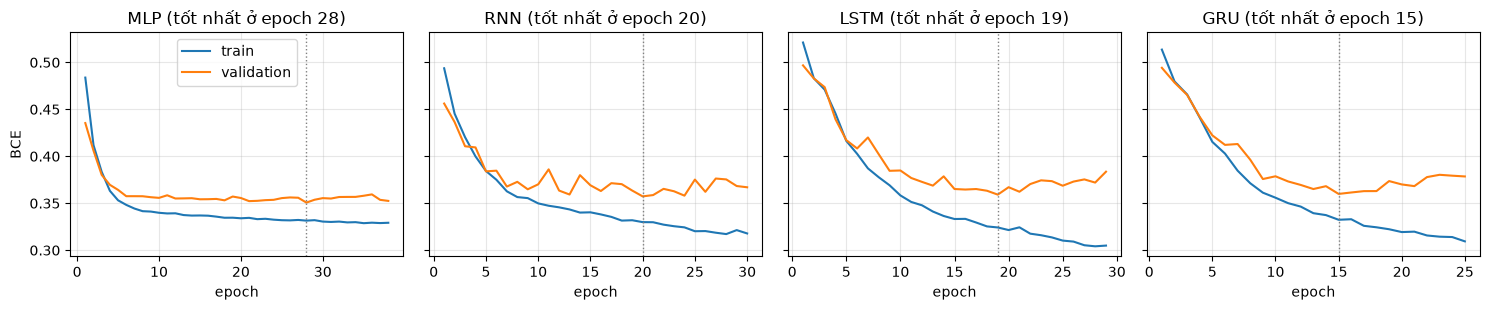

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, (name, runs) in zip(axes, churn_runs.items()):
    h = runs[0]["history"]
    ep = np.arange(1, len(h["train_loss"]) + 1)
    ax.plot(ep, h["train_loss"], label="train")
    ax.plot(ep, h["val_loss"], label="validation")
    ax.axvline(runs[0]["best_epoch"], c="gray", ls=":", lw=1)
    ax.set_title("%s (tốt nhất ở epoch %d)" % (name, runs[0]["best_epoch"]))
    ax.set_xlabel("epoch")
axes[0].set_ylabel("BCE")
axes[0].legend()
fig.tight_layout()
save(fig, "fig_torch_churn_curves.png")
plt.show()

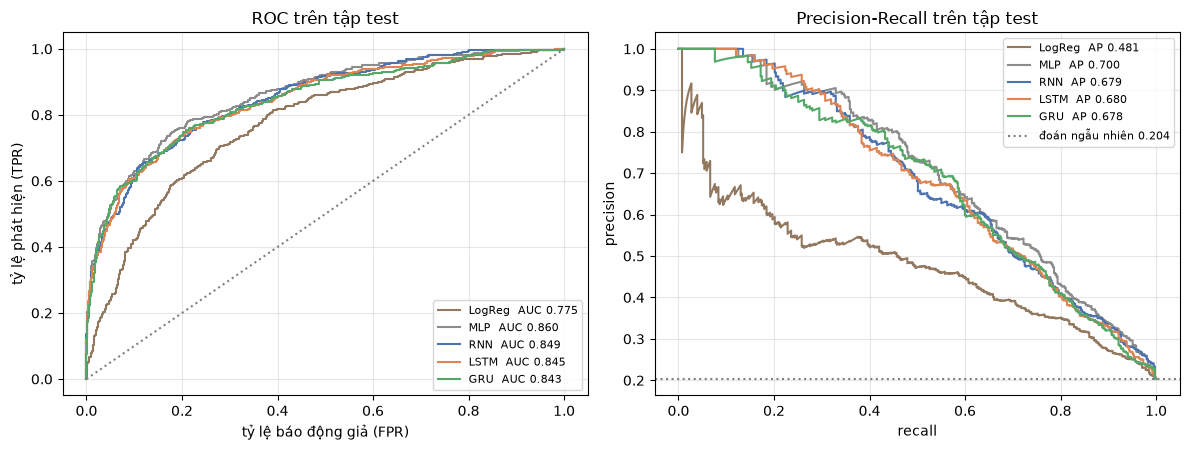

In [7]:
probs = {"LogReg": pt_lr, **{n: r[0]["p_test"] for n, r in churn_runs.items()}}
yt = C["y_test"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(yt, p)
    prec, rec, _ = precision_recall_curve(yt, p)
    auc = logreg["roc_auc"] if name == "LogReg" else churn_runs[name][0]["metrics"]["roc_auc"]
    ap = logreg["pr_auc"] if name == "LogReg" else churn_runs[name][0]["metrics"]["pr_auc"]
    a1.plot(fpr, tpr, c=COLORS[name], label="%s  AUC %.3f" % (name, auc))
    a2.plot(rec, prec, c=COLORS[name], label="%s  AP %.3f" % (name, ap))
a1.plot([0, 1], [0, 1], c="gray", ls=":")
a1.set_xlabel("tỷ lệ báo động giả (FPR)")
a1.set_ylabel("tỷ lệ phát hiện (TPR)")
a1.set_title("ROC trên tập test")
a2.axhline(yt.mean(), c="gray", ls=":", label="đoán ngẫu nhiên %.3f" % yt.mean())
a2.set_xlabel("recall")
a2.set_ylabel("precision")
a2.set_title("Precision-Recall trên tập test")
a1.legend(fontsize=8)
a2.legend(fontsize=8)
fig.tight_layout()
save(fig, "fig_torch_churn_roc_pr.png")
plt.show()

### 3.3. Ma trận nhầm lẫn và phân phối xác suất của LSTM

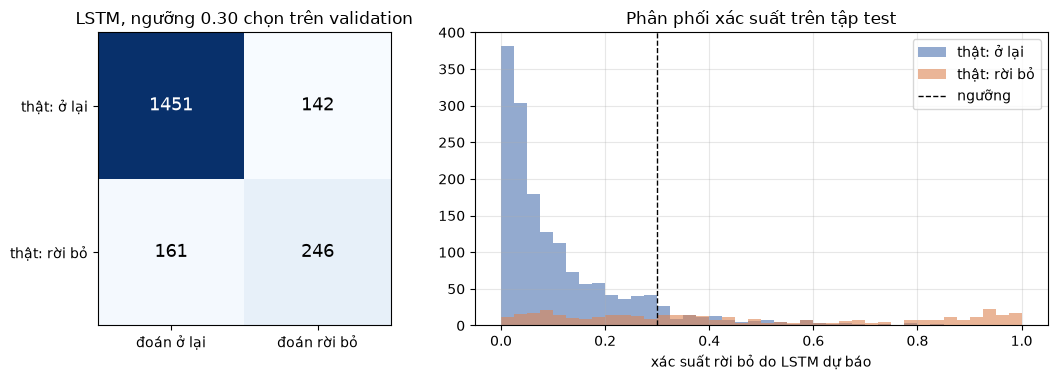

{'roc_auc': 0.8445, 'pr_auc': 0.6797, 'threshold': 0.3, 'accuracy': 0.8485, 'precision': 0.634, 'recall': 0.6044, 'f1': 0.6189, 'accuracy_at_05': 0.852, 'confusion': [[1451, 142], [161, 246]]}


In [8]:
r0 = churn_runs["LSTM"][0]
cm = np.array(r0["metrics"]["confusion"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1, 1.6]})
a1.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        a1.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
a1.set_xticks([0, 1], ["đoán ở lại", "đoán rời bỏ"])
a1.set_yticks([0, 1], ["thật: ở lại", "thật: rời bỏ"])
a1.grid(False)
a1.set_title("LSTM, ngưỡng %.2f chọn trên validation" % r0["metrics"]["threshold"])
bins = np.linspace(0, 1, 41)
a2.hist(r0["p_test"][yt == 0], bins=bins, alpha=0.6, label="thật: ở lại", color="#4C72B0")
a2.hist(r0["p_test"][yt == 1], bins=bins, alpha=0.6, label="thật: rời bỏ", color="#DD8452")
a2.axvline(r0["metrics"]["threshold"], c="k", ls="--", lw=1, label="ngưỡng")
a2.set_xlabel("xác suất rời bỏ do LSTM dự báo")
a2.legend()
a2.set_title("Phân phối xác suất trên tập test")
fig.tight_layout()
save(fig, "fig_torch_churn_confusion.png")
plt.show()
print(r0["metrics"])

### 3.4. Mô hình dựa vào đặc trưng nào, và trạng thái ẩn học được gì

            feature  auc_drop     std
0     NumOfProducts    0.1421  0.0078
1               Age    0.1024  0.0079
2           Balance    0.0270  0.0030
3    IsActiveMember    0.0242  0.0044
4       Geo_Germany    0.0202  0.0042
5       Gender_Male    0.0069  0.0012
6       CreditScore    0.0033  0.0020
7         Geo_Spain    0.0010  0.0036
8   EstimatedSalary    0.0006  0.0028
9            Tenure    0.0002  0.0028
10        HasCrCard   -0.0011  0.0015


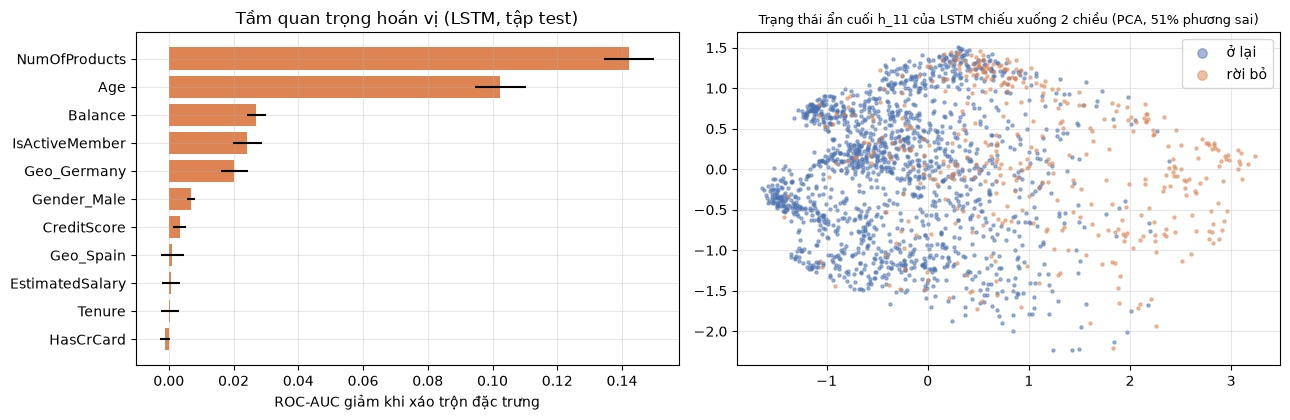

In [9]:
lstm = churn_models["LSTM"]


def lstm_predict(X2d):
    return sigmoid(predict(lstm, as_seq(X2d.astype(np.float32))))


imp = D.permutation_importance(lstm_predict, C["X_test"], C["y_test"], C["features"])
print(imp.round(4))

lstm.eval()
with torch.no_grad():
    _, h_test = lstm(torch.as_tensor(as_seq(C["X_test"])), return_hidden=True)
pca = PCA(n_components=2, random_state=0)
z = pca.fit_transform(h_test.numpy())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.3))
a1.barh(imp["feature"][::-1], imp["auc_drop"][::-1], xerr=imp["std"][::-1],
        color="#DD8452")
a1.set_xlabel("ROC-AUC giảm khi xáo trộn đặc trưng")
a1.set_title("Tầm quan trọng hoán vị (LSTM, tập test)")
for lab, col, name in [(0, "#4C72B0", "ở lại"), (1, "#DD8452", "rời bỏ")]:
    a2.scatter(z[yt == lab, 0], z[yt == lab, 1], s=5, alpha=0.5, c=col, label=name)
a2.set_title("Trạng thái ẩn cuối h_11 của LSTM chiếu xuống 2 chiều (PCA, %.0f%% phương sai)"
             % (100 * pca.explained_variance_ratio_.sum()), fontsize=9)
a2.legend(markerscale=3)
fig.tight_layout()
save(fig, "fig_torch_churn_importance.png")
plt.show()

### 3.5. Thứ tự đọc đặc trưng có quan trọng không?

RNN xử lý chuỗi theo thứ tự, còn 11 đặc trưng của một khách hàng thì không có thứ tự
tự nhiên nào. Nếu kết quả thay đổi khi đổi thứ tự thì thứ tự là một siêu tham số ẩn mà
MLP không có. Thí nghiệm huấn luyện lại LSTM (ba hạt giống cho mỗi thứ tự) với:

- thứ tự gốc và thứ tự đảo ngược;
- 10 hoán vị ngẫu nhiên;
- ba thứ tự thiết kế để kiểm tra một giả thuyết: *LSTM làm tốt hơn khi các đặc trưng
  quan trọng đứng liền nhau*. Nhóm "quan trọng" là 5 đặc trưng có tầm quan trọng hoán
  vị cao nhất đo trên **tập validation** (không dùng tập test để thiết kế thí nghiệm).

Đại lượng đo mức "rải rác" của một thứ tự là độ trải: vị trí cuối trừ vị trí đầu của
5 đặc trưng quan trọng, từ 4 (đứng liền nhau) đến 10 (trải khắp chuỗi).

In [10]:
imp_val = D.permutation_importance(lstm_predict, C["X_val"], C["y_val"], C["features"])
top = list(imp_val["feature"][:5])
rest = [f for f in D.CHURN_SEQ if f not in top]
print("5 dac trung quan trong nhat tren validation:", top)


def spread(order):
    pos = [order.index(f) for f in top]
    return max(pos) - min(pos)


rng = np.random.default_rng(0)
orders = {"gốc": ("gốc, đảo ngược", list(D.CHURN_SEQ)),
          "đảo ngược": ("gốc, đảo ngược", list(D.CHURN_SEQ)[::-1])}
for k in range(10):
    orders["ngẫu nhiên %d" % (k + 1)] = ("ngẫu nhiên", [str(f) for f in rng.permutation(D.CHURN_SEQ)])
orders["liền nhau, ở đầu"] = ("thiết kế", top + rest)
orders["liền nhau, ở cuối"] = ("thiết kế", rest + top[::-1])
orders["xen kẽ, trải rộng"] = ("thiết kế", [top[0], rest[0], rest[1], top[1], rest[2], top[2],
                                            rest[3], top[3], rest[4], rest[5], top[4]])

def order_data(order):
    Co = D.churn_splits(order=order)
    data_o = dict(X_train=as_seq(Co["X_train"]), y_train=Co["y_train"],
                  X_val=as_seq(Co["X_val"]), y_val=Co["y_val"])
    return data_o, as_seq(Co["X_test"])


order_rows, order_hist = [], {}
for oname, (kind, order) in orders.items():
    if oname == "gốc":
        runs = churn_runs["LSTM"]
    else:
        data_o, X_test_o = order_data(order)
        runs = [run_churn(churn_makers["LSTM"], data_o, X_test_o, s)[1] for s in SEEDS]
    aucs = [r["metrics"]["roc_auc"] for r in runs]
    order_hist[oname] = [r["history"]["val_loss"] for r in runs]
    order_rows.append(dict(thu_tu=oname, loai=kind, do_trai=spread(order),
                           auc_tb=float(np.mean(aucs)), auc_std=float(np.std(aucs)),
                           auc_tung_lan=[round(a, 4) for a in aucs],
                           so_epoch=[r["epochs"] for r in runs],
                           thu_tu_day_du=" > ".join(order)))
order_df = pd.DataFrame(order_rows)
print(order_df.drop(columns="thu_tu_day_du").round(4).to_string(index=False))
rho = pd.Series(order_df["do_trai"]).corr(order_df["auc_tb"], method="spearman")
print("tuong quan Spearman giua do trai va AUC tren %d thu tu: %.3f" % (len(order_df), rho))
print("AUC trung binh: tot nhat %.4f, kem nhat %.4f, chenh %.4f | MLP %.4f"
      % (order_df.auc_tb.max(), order_df.auc_tb.min(),
         order_df.auc_tb.max() - order_df.auc_tb.min(), summarize(churn_runs["MLP"], ["roc_auc"])["roc_auc"][0]))

5 dac trung quan trong nhat tren validation: ['NumOfProducts', 'Age', 'Geo_Germany', 'IsActiveMember', 'Balance']


           thu_tu           loai  do_trai  auc_tb  auc_std             auc_tung_lan     so_epoch
              gốc gốc, đảo ngược       10  0.8429   0.0036 [0.8445, 0.8379, 0.8463] [29, 32, 28]
        đảo ngược gốc, đảo ngược       10  0.8456   0.0013 [0.8469, 0.8438, 0.8462] [37, 33, 42]
     ngẫu nhiên 1     ngẫu nhiên        8  0.8445   0.0033  [0.846, 0.8475, 0.8399] [28, 28, 18]
     ngẫu nhiên 2     ngẫu nhiên        4  0.8701   0.0027 [0.8723, 0.8716, 0.8663] [37, 30, 46]
     ngẫu nhiên 3     ngẫu nhiên        8  0.8523   0.0040 [0.8556, 0.8546, 0.8467] [36, 36, 50]
     ngẫu nhiên 4     ngẫu nhiên       10  0.8425   0.0036   [0.8476, 0.84, 0.8398] [18, 29, 16]
     ngẫu nhiên 5     ngẫu nhiên        7  0.8574   0.0037 [0.8592, 0.8522, 0.8608] [31, 35, 31]
     ngẫu nhiên 6     ngẫu nhiên        6  0.8475   0.0049 [0.8474, 0.8416, 0.8535] [31, 40, 41]
     ngẫu nhiên 7     ngẫu nhiên        8  0.8531   0.0027 [0.8501, 0.8525, 0.8567] [31, 40, 43]
     ngẫu nhiên 8     ngẫu nhi

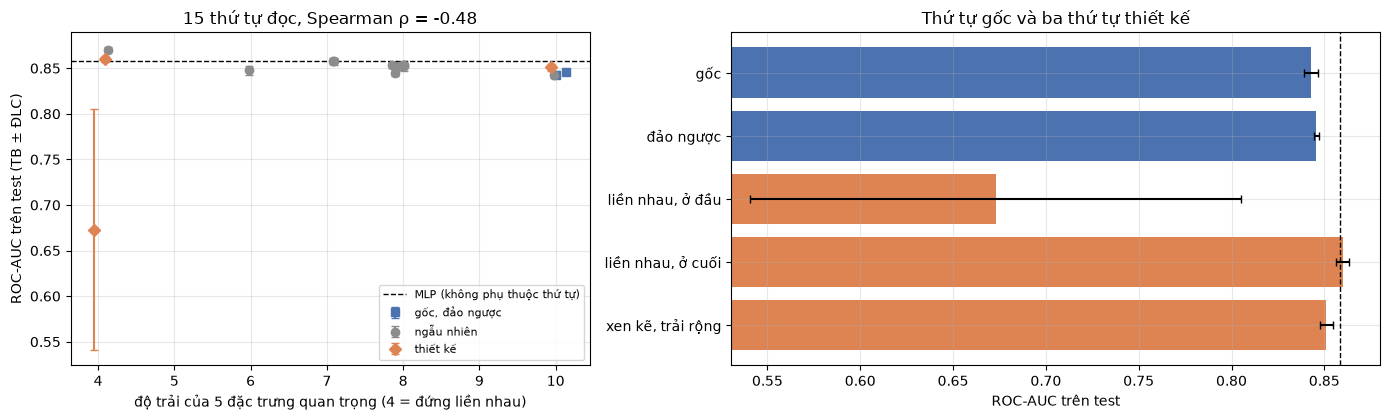

In [11]:
mlp_auc = summarize(churn_runs["MLP"], ["roc_auc"])["roc_auc"][0]
style = {"gốc, đảo ngược": ("#4C72B0", "s"), "ngẫu nhiên": ("#8C8C8C", "o"), "thiết kế": ("#DD8452", "D")}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1, 1.25]})
jit = np.random.default_rng(1).uniform(-0.15, 0.15, len(order_df))
for kind, (col, mk) in style.items():
    d = order_df[order_df["loai"] == kind]
    a1.errorbar(d["do_trai"] + jit[d.index], d["auc_tb"], yerr=d["auc_std"], fmt=mk, c=col,
                capsize=3, label=kind)
a1.axhline(mlp_auc, c="k", ls="--", lw=1, label="MLP (không phụ thuộc thứ tự)")
a1.set_xlabel("độ trải của 5 đặc trưng quan trọng (4 = đứng liền nhau)")
a1.set_ylabel("ROC-AUC trên test (TB ± ĐLC)")
a1.set_title("15 thứ tự đọc, Spearman ρ = %.2f" % rho)
a1.legend(fontsize=8)
d = order_df[order_df["loai"] != "ngẫu nhiên"]
cols = [style[k][0] for k in d["loai"]]
a2.barh(d["thu_tu"][::-1], d["auc_tb"][::-1], xerr=d["auc_std"][::-1], color=cols[::-1], capsize=3)
a2.axvline(mlp_auc, c="k", ls="--", lw=1)
a2.set_xlim(min(0.82, float((d["auc_tb"] - d["auc_std"]).min()) - 0.01), 0.88)
a2.set_xlabel("ROC-AUC trên test")
a2.set_title("Thứ tự gốc và ba thứ tự thiết kế")
fig.tight_layout()
save(fig, "fig_torch_churn_order.png")
plt.show()

Thứ tự "liền nhau, ở đầu" có độ lệch chuẩn giữa các hạt giống lớn bất thường. Ô dưới
xem loss validation theo từng epoch của hai thứ tự thiết kế, rồi huấn luyện lại thứ tự
"ở đầu" với ngân sách dài hơn (tối đa 150 epoch, patience 30) để phân biệt hai khả
năng: mô hình *không thể* học từ đặc trưng ở đầu chuỗi, hay chỉ học *chậm* và bị dừng
sớm cắt ngang.

liền nhau, ở đầu   patience 10: AUC tung hat giong [0.8601, 0.5787, 0.5799], so epoch [60, 19, 24]
liền nhau, ở cuối  patience 10: AUC tung hat giong [0.8569, 0.8647, 0.8581], so epoch [28, 29, 28]
liền nhau, ở đầu   patience 30: AUC tung hat giong [0.8601, 0.8633, 0.8653], epoch tot nhat [59, 79, 106]


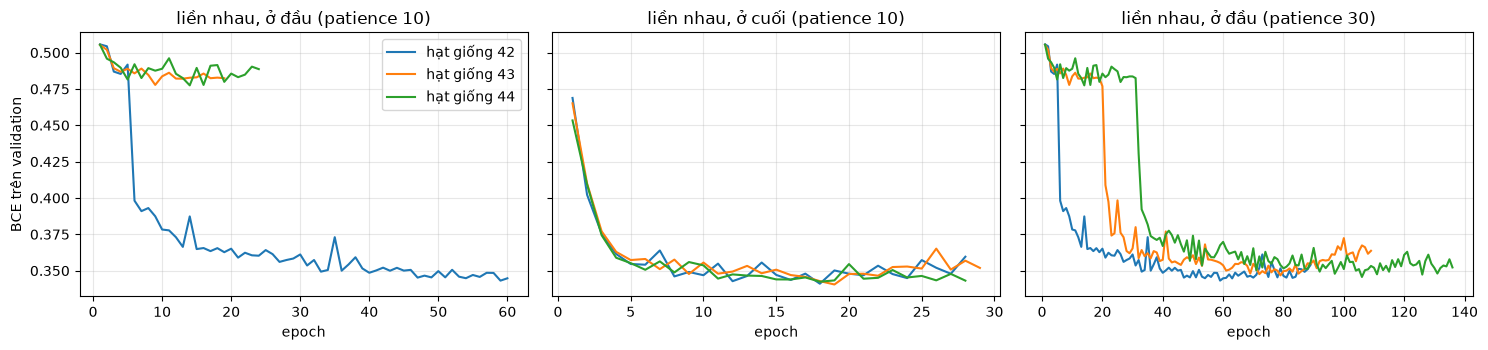

In [12]:
long_hp = dict(D.CHURN_HP, epochs=150, patience=30)
data_o, X_test_o = order_data(orders["liền nhau, ở đầu"][1])
long_runs = [run_churn(churn_makers["LSTM"], data_o, X_test_o, s, long_hp)[1] for s in SEEDS]
order_long = [dict(seed=r["seed"], auc=r["metrics"]["roc_auc"], epochs=r["epochs"],
                   best_epoch=r["best_epoch"]) for r in long_runs]
for name in ("liền nhau, ở đầu", "liền nhau, ở cuối"):
    row = order_df[order_df.thu_tu == name].iloc[0]
    print("%-18s patience 10: AUC tung hat giong %s, so epoch %s"
          % (name, row["auc_tung_lan"], row["so_epoch"]))
print("liền nhau, ở đầu   patience 30: AUC tung hat giong %s, epoch tot nhat %s"
      % ([round(r["auc"], 4) for r in order_long], [r["best_epoch"] for r in order_long]))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
panels = [("liền nhau, ở đầu (patience 10)", order_hist["liền nhau, ở đầu"]),
          ("liền nhau, ở cuối (patience 10)", order_hist["liền nhau, ở cuối"]),
          ("liền nhau, ở đầu (patience 30)", [r["history"]["val_loss"] for r in long_runs])]
for ax, (title, hists) in zip(axes, panels):
    for s, h in zip(SEEDS, hists):
        ax.plot(np.arange(1, len(h) + 1), h, label="hạt giống %d" % s)
    ax.set_title(title)
    ax.set_xlabel("epoch")
axes[0].set_ylabel("BCE trên validation")
axes[0].legend()
fig.tight_layout()
save(fig, "fig_torch_churn_order_curves.png")
plt.show()

## 4. AMZN bài toán 1: dự báo lợi suất phiên kế tiếp

In [13]:
mse = nn.MSELoss()
HS = D.STOCK_HP["hidden"]


def run_stock(S, cell, seed):
    torch.manual_seed(seed)
    model = SeqNet(cell, len(S["features"]), HS, dropout=D.STOCK_HP["dropout"])
    info = fit(model, S, mse, D.STOCK_HP, seed)
    pred = D.unscale(S, predict(model, S["X_test"]))
    return model, dict(seed=seed, metrics=D.reg_metrics(S, pred), pred=pred, **info)


def stock_experiment(target):
    S = D.stock_splits(target)
    base = D.stock_baselines(S)
    runs, models = {}, {}
    for cell in ("RNN", "LSTM", "GRU"):
        runs[cell] = []
        for seed in SEEDS:
            model, r = run_stock(S, cell, seed)
            runs[cell].append(r)
            if seed == SEEDS[0]:
                models[cell] = model
            print("%s %-4s seed %d: RMSE %.6f  %2d epoch  %5.1f s"
                  % (target, cell, seed, r["metrics"]["rmse"], r["epochs"], r["seconds"]))
    return S, base, runs, models


S_ret, base_ret, ret_runs, ret_models = stock_experiment("y_ret")

y_ret RNN  seed 42: RMSE 0.023794  15 epoch   18.6 s


y_ret RNN  seed 43: RMSE 0.023947   9 epoch   11.0 s


y_ret RNN  seed 44: RMSE 0.023807   9 epoch   11.0 s


y_ret LSTM seed 42: RMSE 0.023854  17 epoch   15.4 s


y_ret LSTM seed 43: RMSE 0.023828   9 epoch   10.5 s


y_ret LSTM seed 44: RMSE 0.023846  12 epoch   11.4 s


y_ret GRU  seed 42: RMSE 0.023830  15 epoch   48.2 s


y_ret GRU  seed 43: RMSE 0.023900  32 epoch  103.9 s


y_ret GRU  seed 44: RMSE 0.023881  12 epoch   40.3 s


In [14]:
RET_KEYS = ["rmse", "mae", "r2_vs_zero", "dir_acc", "price_rmse", "price_mape"]
rows = []
for bname, pred in base_ret.items():
    if bname.startswith("_"):
        continue
    m = D.reg_metrics(S_ret, pred)
    rows.append(dict(model=bname, **{k: "%.5f" % m[k] for k in RET_KEYS}, pred_std="%.5f" % np.std(pred)))
for cell, runs in ret_runs.items():
    s = summarize(runs, RET_KEYS)
    rows.append(dict(model=cell, **{k: "%.5f ± %.5f" % s[k] for k in RET_KEYS},
                     pred_std="%.5f" % np.mean([np.std(r["pred"]) for r in runs])))
ret_table = pd.DataFrame(rows).set_index("model")
print("ty le phien tang trong tap test: %.4f | alpha cua Ridge: %s"
      % (base_ret["_up_share_test"], base_ret["_ridge_alpha"]))
print("do lech chuan cua loi suat that trong tap test: %.5f" % np.std(S_ret["yraw_test"]))
ret_table

ty le phien tang trong tap test: 0.5082 | alpha cua Ridge: 10000
do lech chuan cua loi suat that trong tap test: 0.02376


,rmse,mae,r2_vs_zero,dir_acc,price_rmse,price_mape,pred_std
model,,,,,,,
Naive (loi suat 0),0.02376,0.01705,0.00000,nan,3.09818,1.70616,0.00000
Trung binh train,0.02379,0.01706,-0.00296,0.50815,3.10553,1.70899,0.00000
Ridge (cua so 60 ngay),0.02387,0.01710,-0.00926,0.50408,3.11911,1.71354,0.00178
RNN,0.02385 ± 0.00007,0.01713 ± 0.00009,-0.00775 ± 0.00585,0.50951 ± 0.00967,3.11442 ± 0.01204,1.71775 ± 0.00990,0.00108
LSTM,0.02384 ± 0.00001,0.01710 ± 0.00001,-0.00718 ± 0.00091,0.50589 ± 0.00320,3.11170 ± 0.00027,1.71389 ± 0.00087,0.00058
GRU,0.02387 ± 0.00003,0.01713 ± 0.00005,-0.00952 ± 0.00251,0.50725 ± 0.00064,3.11678 ± 0.00495,1.71779 ± 0.00491,0.00118


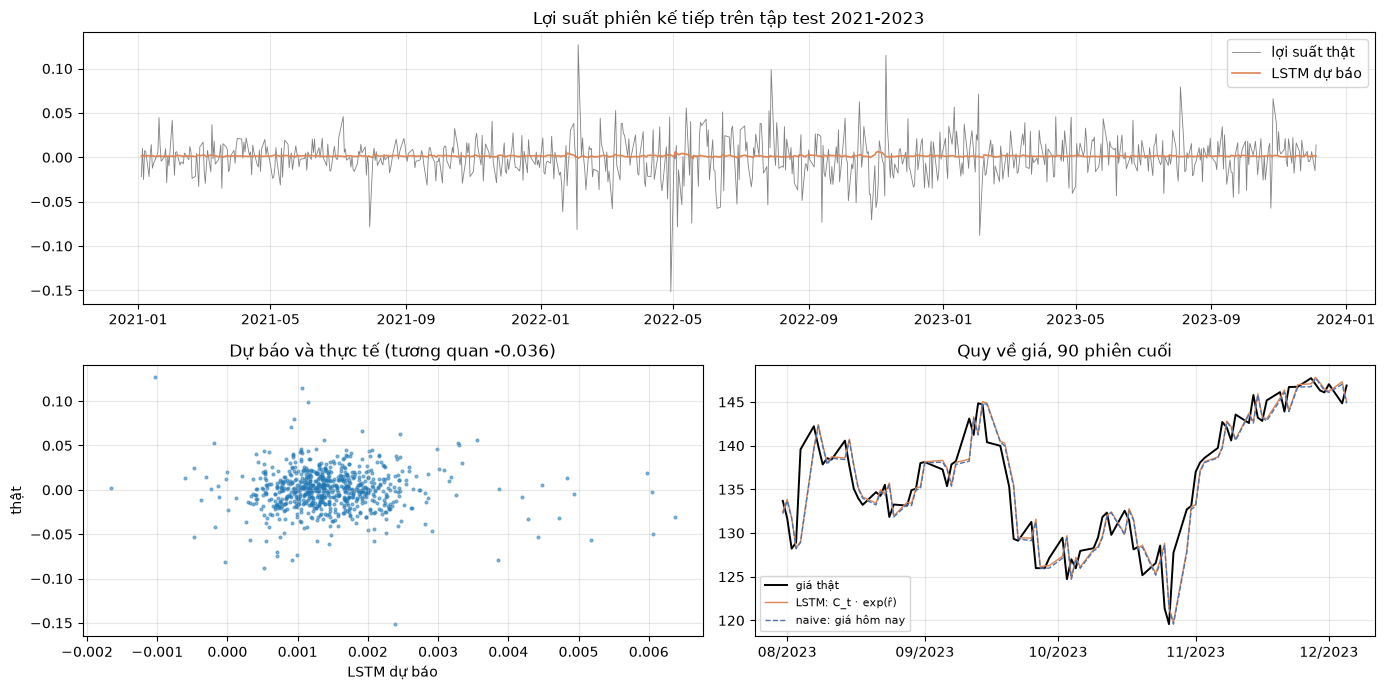

In [15]:
lstm_ret = ret_runs["LSTM"][0]
dates = S_ret["date_test"]
fig = plt.figure(figsize=(14, 7))
ax1 = fig.add_subplot(2, 2, (1, 2))
ax1.plot(dates, S_ret["yraw_test"], lw=0.6, c="gray", label="lợi suất thật")
ax1.plot(dates, lstm_ret["pred"], lw=1.2, c="#DD8452", label="LSTM dự báo")
ax1.set_title("Lợi suất phiên kế tiếp trên tập test 2021-2023")
ax1.legend()
ax2 = fig.add_subplot(2, 2, 3)
ax2.scatter(lstm_ret["pred"], S_ret["yraw_test"], s=4, alpha=0.5)
ax2.set_xlabel("LSTM dự báo")
ax2.set_ylabel("thật")
ax2.set_title("Dự báo và thực tế (tương quan %.3f)" % lstm_ret["metrics"]["corr"])
ax3 = fig.add_subplot(2, 2, 4)
last = slice(-90, None)
p_price = S_ret["close_t_test"] * np.exp(lstm_ret["pred"])
ax3.plot(dates[last], S_ret["close_next_test"][last], c="k", lw=1.4, label="giá thật")
ax3.plot(dates[last], p_price[last], c="#DD8452", lw=1, label="LSTM: C_t · exp(r̂)")
ax3.plot(dates[last], S_ret["close_t_test"][last], c="#4C72B0", lw=1, ls="--",
         label="naive: giá hôm nay")
ax3.set_title("Quy về giá, 90 phiên cuối")
ax3.xaxis.set_major_locator(mdates.MonthLocator())
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax3.legend(fontsize=8)
fig.tight_layout()
save(fig, "fig_torch_ret_test.png")
plt.show()

## 5. Cái bẫy "dự báo giá trông rất đẹp"

Nhiều bài hướng dẫn đưa thẳng giá đóng cửa (chuẩn hóa min-max) vào LSTM rồi vẽ đường
dự báo gần như trùng đường giá thật. Mục này làm đúng như vậy để đo xem đường đẹp đó
thực chất là gì. Hai phép đo: so sai số với dự báo naive "giá mai bằng giá hôm nay",
và `lag_profile` đo xem dự báo của ngày t giống giá thật của ngày nào nhất.

{'lstm_price_rmse': 7.933, 'naive_price_rmse': 3.098, 'lstm_mape': 4.391, 'naive_mape': 1.706, 'train_max': 101.976, 'test_max': 186.57, 'pred_max': 168.475, 'epochs': 40}
 lag_k  rmse
     0 7.933
     1 7.431
     2 7.120
     3 7.024
     4 7.123
     5 7.370


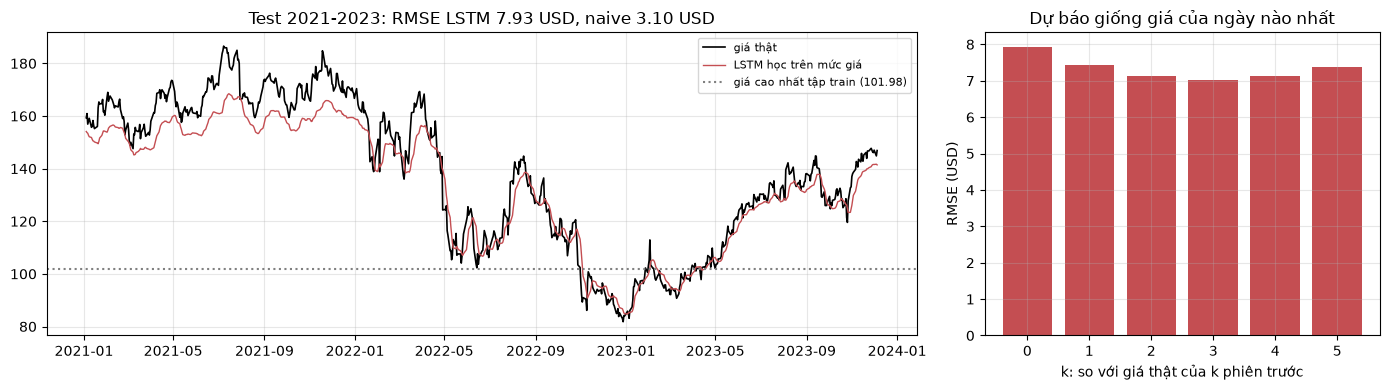

In [16]:
P = D.price_level_splits()
torch.manual_seed(SEEDS[0])
trap = SeqNet("LSTM", 1, HS)
trap_info = fit(trap, P, mse, D.STOCK_HP, SEEDS[0])
trap_pred = predict(trap, P["X_test"]) * (P["hi"] - P["lo"]) + P["lo"]
c1, c0 = P["close_next_test"], P["close_t_test"]
trap_res = dict(
    lstm_price_rmse=float(np.sqrt(np.mean((trap_pred - c1) ** 2))),
    naive_price_rmse=float(np.sqrt(np.mean((c0 - c1) ** 2))),
    lstm_mape=float(np.mean(np.abs(trap_pred - c1) / c1) * 100),
    naive_mape=float(np.mean(np.abs(c0 - c1) / c1) * 100),
    train_max=P["hi"], test_max=float(c1.max()), pred_max=float(trap_pred.max()),
    epochs=trap_info["epochs"])
lag = D.lag_profile(trap_pred, c1)
print({k: round(v, 3) if isinstance(v, float) else v for k, v in trap_res.items()})
print(lag.round(3).to_string(index=False))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.2, 1]})
a1.plot(P["date_test"], c1, c="k", lw=1.2, label="giá thật")
a1.plot(P["date_test"], trap_pred, c="#C44E52", lw=1, label="LSTM học trên mức giá")
a1.axhline(P["hi"], c="gray", ls=":", label="giá cao nhất tập train (%.2f)" % P["hi"])
a1.set_title("Test 2021-2023: RMSE LSTM %.2f USD, naive %.2f USD"
             % (trap_res["lstm_price_rmse"], trap_res["naive_price_rmse"]))
a1.legend(fontsize=8)
a2.bar(lag["lag_k"], lag["rmse"], color="#C44E52")
a2.set_xlabel("k: so với giá thật của k phiên trước")
a2.set_ylabel("RMSE (USD)")
a2.set_title("Dự báo giống giá của ngày nào nhất")
fig.tight_layout()
save(fig, "fig_torch_price_trap.png")
plt.show()

## 6. AMZN bài toán 2: dự báo biến động 5 phiên tới

In [17]:
S_vol, base_vol, vol_runs, vol_models = stock_experiment("y_vol")

y_vol RNN  seed 42: RMSE 0.009923  25 epoch   31.0 s


y_vol RNN  seed 43: RMSE 0.009797  12 epoch   14.9 s


y_vol RNN  seed 44: RMSE 0.009666  22 epoch   27.6 s


y_vol LSTM seed 42: RMSE 0.009799  24 epoch   22.2 s


y_vol LSTM seed 43: RMSE 0.009809  26 epoch   26.4 s


y_vol LSTM seed 44: RMSE 0.010016  32 epoch   32.1 s


y_vol GRU  seed 42: RMSE 0.009689  23 epoch   75.1 s


y_vol GRU  seed 43: RMSE 0.009627  24 epoch   79.4 s


y_vol GRU  seed 44: RMSE 0.009651  19 epoch   62.9 s


In [18]:
VOL_KEYS = ["rmse", "mae", "r2", "corr"]
rows = []
for bname, pred in base_vol.items():
    if bname.startswith("_"):
        continue
    m = D.reg_metrics(S_vol, pred)
    rows.append(dict(model=bname, **{k: "%.5f" % m[k] for k in VOL_KEYS}))
for cell, runs in vol_runs.items():
    s = summarize(runs, VOL_KEYS)
    rows.append(dict(model=cell, **{k: "%.5f ± %.5f" % s[k] for k in VOL_KEYS},
                     epochs="%.0f" % np.mean([r["epochs"] for r in runs]),
                     seconds="%.1f" % np.mean([r["seconds"] for r in runs])))
vol_table = pd.DataFrame(rows).set_index("model")
vol_table

,rmse,mae,r2,corr,epochs,seconds
model,,,,,,
Bien dong 20 ngay qua,0.01148,0.00834,-0.02187,0.37504,NaN,NaN
Trung binh train,0.01397,0.01221,-0.51349,0.00000,NaN,NaN
Ridge (cua so 60 ngay),0.00968,0.00663,0.27316,0.52932,NaN,NaN
RNN,0.00980 ± 0.00010,0.00652 ± 0.00011,0.25543 ± 0.01596,0.51411 ± 0.01963,20,24.5
LSTM,0.00987 ± 0.00010,0.00660 ± 0.00003,0.24330 ± 0.01540,0.50128 ± 0.01233,27,26.9
GRU,0.00966 ± 0.00003,0.00648 ± 0.00001,0.27661 ± 0.00383,0.53750 ± 0.00171,22,72.5


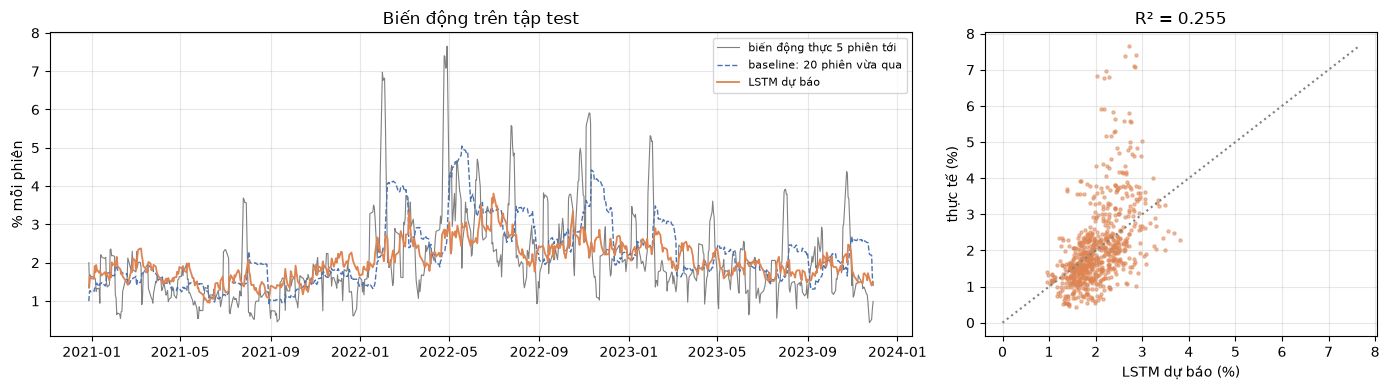

In [19]:
lstm_vol = vol_runs["LSTM"][0]
dv = S_vol["date_test"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.2, 1]})
a1.plot(dv, S_vol["yraw_test"] * 100, c="gray", lw=0.8, label="biến động thực 5 phiên tới")
a1.plot(dv, base_vol["Bien dong 20 ngay qua"] * 100, c="#4C72B0", lw=1, ls="--",
        label="baseline: 20 phiên vừa qua")
a1.plot(dv, lstm_vol["pred"] * 100, c="#DD8452", lw=1.3, label="LSTM dự báo")
a1.set_ylabel("% mỗi phiên")
a1.set_title("Biến động trên tập test")
a1.legend(fontsize=8)
a2.scatter(lstm_vol["pred"] * 100, S_vol["yraw_test"] * 100, s=5, alpha=0.5, c="#DD8452")
lim = [0, max(S_vol["yraw_test"].max(), lstm_vol["pred"].max()) * 100]
a2.plot(lim, lim, c="gray", ls=":")
a2.set_xlabel("LSTM dự báo (%)")
a2.set_ylabel("thực tế (%)")
a2.set_title("R² = %.3f" % lstm_vol["metrics"]["r2"])
fig.tight_layout()
save(fig, "fig_torch_vol_test.png")
plt.show()

## 7. Ghép hai mô hình: dự báo phiên kế tiếp sau ngày cuối của dữ liệu

Mô hình lợi suất cho điểm giữa, mô hình biến động cho độ rộng khoảng: khoảng 95% của
lợi suất ngày mai lấy là r̂ ± 1,96·σ̂. Trước khi dùng khoảng này cho ngày tương lai,
kiểm tra nó trên tập test: bao nhiêu phần trăm số phiên có lợi suất thật nằm trong
khoảng.

In [20]:
# hai bai toan co ngay du bao dau tien khac nhau (muc tieu 1 phien va 5 phien), nen chi
# so sanh tren nhung ngay co ca hai du bao
common = np.intersect1d(S_ret["date_test"], S_vol["date_test"])
ir = np.isin(S_ret["date_test"], common)
iv = np.isin(S_vol["date_test"], common)
r_true = S_ret["yraw_test"][ir]
lo = ret_runs["LSTM"][0]["pred"][ir] - 1.96 * vol_runs["LSTM"][0]["pred"][iv]
hi = ret_runs["LSTM"][0]["pred"][ir] + 1.96 * vol_runs["LSTM"][0]["pred"][iv]
coverage = float(np.mean((r_true >= lo) & (r_true <= hi)))
print("so phien kiem tra: %d | ty le loi suat that nam trong khoang 95%%: %.2f%%"
      % (len(r_true), 100 * coverage))

x_last, last_date, last_close = D.last_window(S_ret)
r_hat = float(D.unscale(S_ret, predict(ret_models["LSTM"], x_last))[0])
s_hat = float(D.unscale(S_vol, predict(vol_models["LSTM"], x_last))[0])
forecast = dict(last_date=str(last_date.date()), last_close=last_close, r_hat=r_hat,
                sigma_hat=s_hat, price_hat=last_close * np.exp(r_hat),
                price_lo=last_close * np.exp(r_hat - 1.96 * s_hat),
                price_hi=last_close * np.exp(r_hat + 1.96 * s_hat), coverage_test=coverage)
print({k: (round(v, 5) if isinstance(v, float) else v) for k, v in forecast.items()})

so phien kiem tra: 732 | ty le loi suat that nam trong khoang 95%: 93.72%
{'last_date': '2023-12-05', 'last_close': 146.88001, 'r_hat': 0.00192, 'sigma_hat': 0.01634, 'price_hat': np.float64(147.16289), 'price_lo': np.float64(142.52521), 'price_hi': np.float64(151.95148), 'coverage_test': 0.93716}


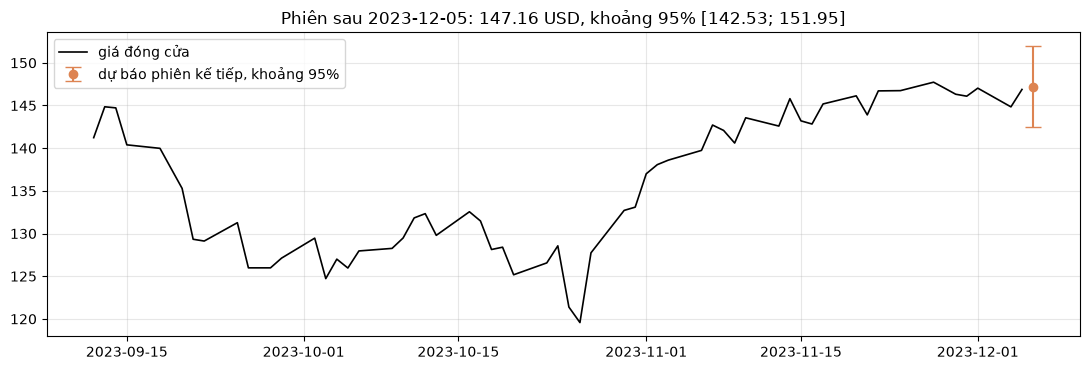

In [21]:
f_all = D.stock_frame()
tail = f_all["close"].iloc[-60:]
nxt = tail.index[-1] + pd.offsets.BDay(1)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(tail.index, tail, c="k", lw=1.2, label="giá đóng cửa")
ax.errorbar([nxt], [forecast["price_hat"]],
            yerr=[[forecast["price_hat"] - forecast["price_lo"]],
                  [forecast["price_hi"] - forecast["price_hat"]]],
            fmt="o", c="#DD8452", capsize=6, label="dự báo phiên kế tiếp, khoảng 95%")
ax.set_title("Phiên sau %s: %.2f USD, khoảng 95%% [%.2f; %.2f]"
             % (forecast["last_date"], forecast["price_hat"], forecast["price_lo"],
                forecast["price_hi"]))
ax.legend()
fig.tight_layout()
save(fig, "fig_torch_forecast.png")
plt.show()

## 8. Ghi kết quả cho notebook so sánh

In [22]:
def pack(runs, keys, extra):
    return dict(runs=[{k: v for k, v in r.items() if k not in ("p_test", "pred", "history")}
                      for r in runs],
                summary={k: list(v) for k, v in summarize(runs, keys).items()},
                history=runs[0]["history"], **extra)


for name, runs in churn_runs.items():
    D.save_result("torch__churn__" + name,
                  pack(runs, KEYS, dict(framework="PyTorch", task="churn", model=name,
                                        params=n_params(churn_models[name]),
                                        p_test=runs[0]["p_test"])))
for cell, runs in ret_runs.items():
    D.save_result("torch__ret__" + cell,
                  pack(runs, RET_KEYS, dict(framework="PyTorch", task="ret", model=cell,
                                            params=n_params(ret_models[cell]),
                                            pred=runs[0]["pred"])))
for cell, runs in vol_runs.items():
    D.save_result("torch__vol__" + cell,
                  pack(runs, VOL_KEYS, dict(framework="PyTorch", task="vol", model=cell,
                                            params=n_params(vol_models[cell]),
                                            pred=runs[0]["pred"])))
D.save_result("baselines", dict(
    churn_logreg=logreg,
    ret={k: D.reg_metrics(S_ret, v) for k, v in base_ret.items() if not k.startswith("_")},
    vol={k: D.reg_metrics(S_vol, v) for k, v in base_vol.items() if not k.startswith("_")},
    up_share_test=base_ret["_up_share_test"]))
D.save_result("torch__extra", dict(order=order_rows, importance=imp.to_dict("records"),
                                    importance_val=imp_val.to_dict("records"), top5_val=top,
                                    order_spearman=rho, order_long=order_long,
                                    price_trap=trap_res, lag=lag.to_dict("records"),
                                    forecast=forecast))
print(sorted(p.name for p in D.RESULTS.glob("*.json")))

['baselines.json', 'concept__memory.json', 'keras__churn__GRU.json', 'keras__churn__LSTM.json', 'keras__churn__MLP.json', 'keras__churn__RNN.json', 'keras__extra.json', 'keras__ret__GRU.json', 'keras__ret__LSTM.json', 'keras__ret__RNN.json', 'keras__vol__GRU.json', 'keras__vol__LSTM.json', 'keras__vol__RNN.json', 'torch__churn__GRU.json', 'torch__churn__LSTM.json', 'torch__churn__MLP.json', 'torch__churn__RNN.json', 'torch__extra.json', 'torch__ret__GRU.json', 'torch__ret__LSTM.json', 'torch__ret__RNN.json', 'torch__vol__GRU.json', 'torch__vol__LSTM.json', 'torch__vol__RNN.json']
